# F1 Driver-Season Clustering: DBSCAN vs Gaussian Mixture Model
**TP Machine Learning, Option 4 (Clustering)**

**Goal:** group Formula 1 driver-seasons (2014–2025) into performance profiles
without labels, and compare a density-based algorithm (DBSCAN) with a
probabilistic one (GMM).

| Notebook section | Charter point |
|---|---|
| 1. Dataset description | 2 |
| 2. Preprocessing | 3 |
| 3. Implementation | 5 |
| 4. Evaluation | 6 |
| 5. Comparison and interpretation | 7 |

Points 1 (problem) and 4 (algorithm theory) are covered in the presentation.

## 0. Setup

In [137]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

In [138]:
# --- Project settings: ---
DATA_RAW = Path("../data/raw")              # original csv
DATA_PROCESSED = Path("../data/processed")  # cleaned data
FIGURES = Path("../figures")                # plots 
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

START_YEAR, END_YEAR = 2014, 2025   # V6 hybrid engines era: 
MIN_STARTS = 8                      
RANDOM_STATE = 42                   # fixed seed (explained at class)

sns.set_theme(style="whitegrid")

## 1. Dataset description (charter point 2)

**Source:** [Formula 1 Race Data](https://www.kaggle.com/datasets/jtrotman/formula-1-race-data)
by jtrotman on Kaggle (Ergast format, CC0 licence): a relational database of 14 CSV
tables covering every race since 1950.

We use 6 tables, because the unit we cluster is one driver in one season:

| Table | Role |
|---|---|
| `races` | links each race to its season (`year`) |
| `results` | one row per driver per race: grid, finish, points, classification |
| `qualifying` | qualifying position: pure pace and teammate comparison |
| `drivers`, `constructors` | names, only to interpret clusters |
| `driver_standings` | final championship position, only to validate clusters |

**Not used:** `lap_times` and `pit_stops` (lap-level, wrong granularity),
`sprint_results` (sprints intreduced at 2021), and the circuit and
constructor-performance tables (focus on drivers).

In [139]:
# Missing values : "\N" in dataset (Ergast convention).
# Without na_values, numeric columns containing "\N" would be loaded as text.
def load(name):
    return pd.read_csv(DATA_RAW / f"{name}.csv", na_values="\\N")

races = load("races")
results = load("results")
qualifying = load("qualifying")
drivers = load("drivers")
constructors = load("constructors")
driver_standings = load("driver_standings")

print(results.grid.dtype)   # must be float64, not object

float64


In [140]:
tables = {"races": races, "results": results, "qualifying": qualifying,
          "drivers": drivers, "constructors": constructors,
          "driver_standings": driver_standings}

overview = pd.DataFrame({
    "rows":          {name: len(t) for name, t in tables.items()},
    "columns":       {name: t.shape[1] for name, t in tables.items()},
    "missing cells": {name: int(t.isna().sum().sum()) for name, t in tables.items()},
})
overview

,rows,columns,missing cells
races,1172,18,11479
results,27700,18,124677
qualifying,11430,9,12426
drivers,867,9,1559
constructors,214,5,0
driver_standings,35838,7,8


In [141]:
print(f"Seasons in the dataset: {races.year.min()} to {races.year.max()}")

era_races = races[races.year.between(START_YEAR, END_YEAR)]
print(f"Races kept ({START_YEAR}-{END_YEAR}): {len(era_races)}")

era_races.groupby("year").size().rename("races").to_frame().T

Seasons in the dataset: 1950 to 2026
Races kept (2014-2025): 252


year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
races,19,19,21,20,21,21,17,22,22,22,24,24


The number of races changes between seasons (17 in 2020 because of Covid,
24 in 2024–2025). This is why every feature will be an **average per race**,
not a season total: totals would favour seasons with more races.

In [142]:
era_results = results[results.raceId.isin(era_races.raceId)]

used_cols = ["raceId", "driverId", "constructorId", "grid",
             "position", "positionText", "points"]
era_results[used_cols].isna().sum().rename("missing values").to_frame().T

,raceId,driverId,constructorId,grid,position,positionText,points
missing values,0,0,0,20,721,0,0


`position` is empty when a driver was not classified (DNF): this is expected,
not an error. `grid` has a few missing values (one race without grid data in
the source); we handle them in preprocessing.

In [143]:
# Group every numeric code under "classified" so the letters stand out
codes = era_results.positionText.where(~era_results.positionText.str.isnumeric(), "classified")
codes.value_counts()

positionText
classified    4329
R              726
W               31
D               17
N                1
E                1
Name: count, dtype: int64

`positionText` gives the official classification of each entry:

| Code | Meaning | How we treat it |
|---|---|---|
| a number | classified finish | finished |
| R | retired | DNF |
| D | disqualified | DNF |
| N | not classified | DNF |
| E | excluded | DNF |
| W | withdrawn: did not start | removed |
| F | failed to qualify: did not start | removed |

We use `positionText` rather than the `status` table, because status labels
changed format over the years while this code stays consistent.

## 2. Preprocessing and feature engineering (charter point 3)

The raw data has one row per driver per race. We turn it into **one row per
driver-season**, described by performance features. Each step gives its reason.

### 2.1 Keep the 2014–2025 era and remove non-starters
- **Era:** 2014 introduced the V6 hybrid power units, whose rules stayed in force
  until 2025. 2026 is excluded: new rules, and the season is not finished.
- **Non-starters:** `W` (withdrawn) and `F` (failed to qualify) never took the
  start. Counting them as starts would distort every per-race average.

In [144]:
# Attach the season (year) to every result, then keep our era only
df = results.merge(races[["raceId", "year", "round"]], on="raceId")
df = df[df.year.between(START_YEAR, END_YEAR)].copy()
n_entries = len(df)

# Remove drivers who never started the race
df = df[~df.positionText.isin(["W", "F"])].copy()
print(f"Entries: {n_entries}  ->  starts kept: {len(df)}  (removed {n_entries - len(df)} non-starters)")

Entries: 5105  ->  starts kept: 5074  (removed 31 non-starters)


### 2.2 Fix the starting grid
- `grid = 0` means a **pit-lane start**, behind everyone. Left as 0 it would
  count as starting ahead of pole and make "positions gained" wrong, so we
  replace it with the number of starters in that race.
- A missing `grid` (one race has no grid data in the source) is filled with
  the driver's **qualifying position**, the closest pre-race value.

In [145]:
# Bring in each driver's qualifying position for the same race
quali_pos = qualifying[["raceId", "driverId", "position"]].rename(columns={"position": "quali_pos"})
df = df.merge(quali_pos, on=["raceId", "driverId"], how="left", validate="m:1")

# Number of starters in each race, repeated on every row of that race
starters = df.groupby("raceId").driverId.transform("count")

pit_lane = df.grid == 0
missing_grid = df.grid.isna()
df.loc[pit_lane, "grid"] = starters[pit_lane]
df["grid"] = df.grid.fillna(df.quali_pos).fillna(starters)   # last resort: back of the grid

print(f"Pit-lane starts fixed: {pit_lane.sum()}  |  missing grids filled: {missing_grid.sum()}")

Pit-lane starts fixed: 73  |  missing grids filled: 20


### 2.3 Finished or DNF
A start counts as **finished** when `positionText` is a number (officially
classified) and as a **DNF** otherwise (R, D, N, E).
"Positions gained" (grid − finish) is only computed for finished races:
for a DNF there is no finishing position to compare.

In [146]:
df["finished"] = df.positionText.str.isnumeric()
df["dnf"] = ~df.finished
df["gained"] = np.where(df.finished, df.grid - df.position, np.nan)

df[["finished", "dnf"]].mean().rename("share of starts").to_frame().T

,finished,dnf
share of starts,0.853173,0.146827


### 2.4 Aggregate per driver-season

| Feature | Meaning |
|---|---|
| `avg_finish` | average finishing position, classified finishes only |
| `avg_positions_gained` | average of grid − finish: racecraft and overtaking |
| `dnf_rate` | share of starts not classified: reliability and incidents |
| `points_per_race` | Grand Prix points ÷ starts: overall output |
| `starts` | number of starts, for filtering only (not a feature) |

Every feature is an **average per race**, because seasons had between 17 and
24 races: totals would favour longer seasons.

In [147]:
season = (df.groupby(["driverId", "year"])
            .agg(starts=("raceId", "count"),
                 avg_finish=("position", "mean"),     # mean() skips NaN, so DNFs are ignored here
                 avg_positions_gained=("gained", "mean"),
                 dnf_rate=("dnf", "mean"),
                 points=("points", "sum"))
            .reset_index())

season["points_per_race"] = season.points / season.starts
season = season.drop(columns="points")

print(f"Driver-seasons: {len(season)}")
season.head()

Driver-seasons: 267


,driverId,year,starts,avg_finish,avg_positions_gained,dnf_rate,points_per_race
0,1,2014,19,1.437500,3.250000,0.157895,20.210526
1,1,2015,19,1.722222,-0.333333,0.052632,20.052632
2,1,2016,21,2.105263,2.368421,0.095238,18.095238
3,1,2017,20,2.700000,0.900000,0.000000,18.150000
4,1,2018,21,1.950000,0.800000,0.047619,19.428571


### 2.5 Qualifying pace and teammate head-to-head
- `avg_quali_pos` uses `qualifying.position`, not `grid`: the grid includes
  penalties (engine or gearbox changes), qualifying measures pure pace.
- `teammate_quali_h2h` = share of qualifying sessions where the driver beat
  his teammate. Both drivers have the same car, so this is the one feature
  that **separates the driver from the car**. It is computed race by race,
  so mid-season team changes are handled correctly.

In [148]:
q = qualifying.merge(races[["raceId", "year"]], on="raceId")
q = q[q.year.between(START_YEAR, END_YEAR)].dropna(subset=["position"])

avg_quali = q.groupby(["driverId", "year"]).position.mean().rename("avg_quali_pos").reset_index()

# Self-join: pair every driver with every other driver of the same team in the same race
pairs = q.merge(q[["raceId", "constructorId", "driverId", "position"]],
                on=["raceId", "constructorId"], suffixes=("", "_mate"))
pairs = pairs[pairs.driverId != pairs.driverId_mate]      # a driver is not his own teammate
pairs["beat_mate"] = pairs.position < pairs.position_mate  # lower position = qualified ahead

h2h = (pairs.groupby(["driverId", "year"])
            .agg(teammate_quali_h2h=("beat_mate", "mean"),
                 duels=("beat_mate", "size"))
            .reset_index())

season = (season.merge(avg_quali, on=["driverId", "year"], how="left")
                .merge(h2h, on=["driverId", "year"], how="left"))

season[["avg_quali_pos", "teammate_quali_h2h"]].isna().sum()

avg_quali_pos         0
teammate_quali_h2h    0
dtype: int64

### 2.6 Remove short seasons
Stand-ins and drivers replaced mid-season have only a few starts. Averages
over 2–3 races are mostly noise and would be clustered as if they were real
profiles. We keep driver-seasons with at least `MIN_STARTS` starts.

In [149]:
n_before = len(season)
season = season[season.starts >= MIN_STARTS].reset_index(drop=True)
print(f"Driver-seasons: {n_before}  ->  {len(season)}  (removed {n_before - len(season)} with fewer than {MIN_STARTS} starts)")

Driver-seasons: 267  ->  246  (removed 21 with fewer than 8 starts)


### 2.7 Interpretation columns (never given to the algorithms)
Driver name, main team that season (the team he started for most often) and
final championship position. They are only used afterwards, to name and check
the clusters.

In [150]:
drivers["driver"] = drivers.forename + " " + drivers.surname
season = season.merge(drivers[["driverId", "driver", "code"]], on="driverId", how="left")

# Main team = the constructor the driver started for most often that season
main_team = (df.groupby(["driverId", "year"]).constructorId
               .agg(lambda s: s.value_counts().idxmax())
               .reset_index()
               .merge(constructors[["constructorId", "name"]], on="constructorId")
               .rename(columns={"name": "team"})
               .drop(columns="constructorId"))
season = season.merge(main_team, on=["driverId", "year"], how="left")

# Final standings = standings after the last round of each season
last_round = races.loc[races.groupby("year")["round"].idxmax(), ["raceId", "year"]]
final = (driver_standings.merge(last_round, on="raceId")[["driverId", "year", "position"]]
                         .rename(columns={"position": "champ_pos"}))
season = season.merge(final, on=["driverId", "year"], how="left")

season.sort_values(["year", "champ_pos"]).head(10)

,driverId,year,starts,avg_finish,avg_positions_gained,dnf_rate,points_per_race,avg_quali_pos,teammate_quali_h2h,duels,driver,code,team,champ_pos
0,1,2014,19,1.437500,3.250000,0.157895,20.210526,3.947368,0.368421,19,Lewis Hamilton,HAM,Mercedes,1.0
12,3,2014,19,2.529412,-0.823529,0.105263,16.684211,1.684211,0.631579,19,Nico Rosberg,ROS,Mercedes,2.0
81,817,2014,19,3.750000,2.687500,0.157895,12.526316,5.000000,0.611111,18,Daniel Ricciardo,RIC,Red Bull,3.0
95,822,2014,19,5.555556,0.277778,0.052632,9.789474,6.000000,0.684211,19,Valtteri Bottas,BOT,Williams,4.0
42,20,2014,19,5.062500,2.437500,0.157895,8.789474,7.055556,0.388889,18,Sebastian Vettel,VET,Red Bull,5.0
15,4,2014,19,5.411765,1.176471,0.105263,8.473684,6.789474,0.842105,19,Fernando Alonso,ALO,Ferrari,6.0
34,13,2014,19,7.375000,-0.187500,0.157895,7.052632,7.684211,0.315789,19,Felipe Massa,MAS,Williams,7.0
39,18,2014,19,7.500000,0.833333,0.052632,6.631579,8.368421,0.526316,19,Jenson Button,BUT,McLaren,8.0
59,807,2014,19,7.705882,3.235294,0.105263,5.052632,10.894737,0.631579,19,Nico Hülkenberg,HUL,Force India,9.0
70,815,2014,18,8.866667,3.266667,0.166667,3.277778,12.105263,0.368421,19,Sergio Pérez,PER,Force India,10.0


### 2.8 Feature distributions
Skewed features and extreme values matter for DBSCAN, which works with distances.

,count,mean,std,min,25%,50%,75%,max
avg_quali_pos,246.0,10.71,4.87,1.58,6.80,11.00,14.32,20.81
avg_finish,246.0,9.48,4.16,1.27,6.35,9.90,12.68,18.22
avg_positions_gained,246.0,1.27,1.37,-1.94,0.29,1.13,2.23,5.15
dnf_rate,246.0,0.15,0.10,0.00,0.08,0.14,0.21,0.47
points_per_race,246.0,4.99,5.62,0.00,0.62,2.50,8.39,24.09
teammate_quali_h2h,246.0,0.50,0.25,0.00,0.32,0.50,0.68,1.00


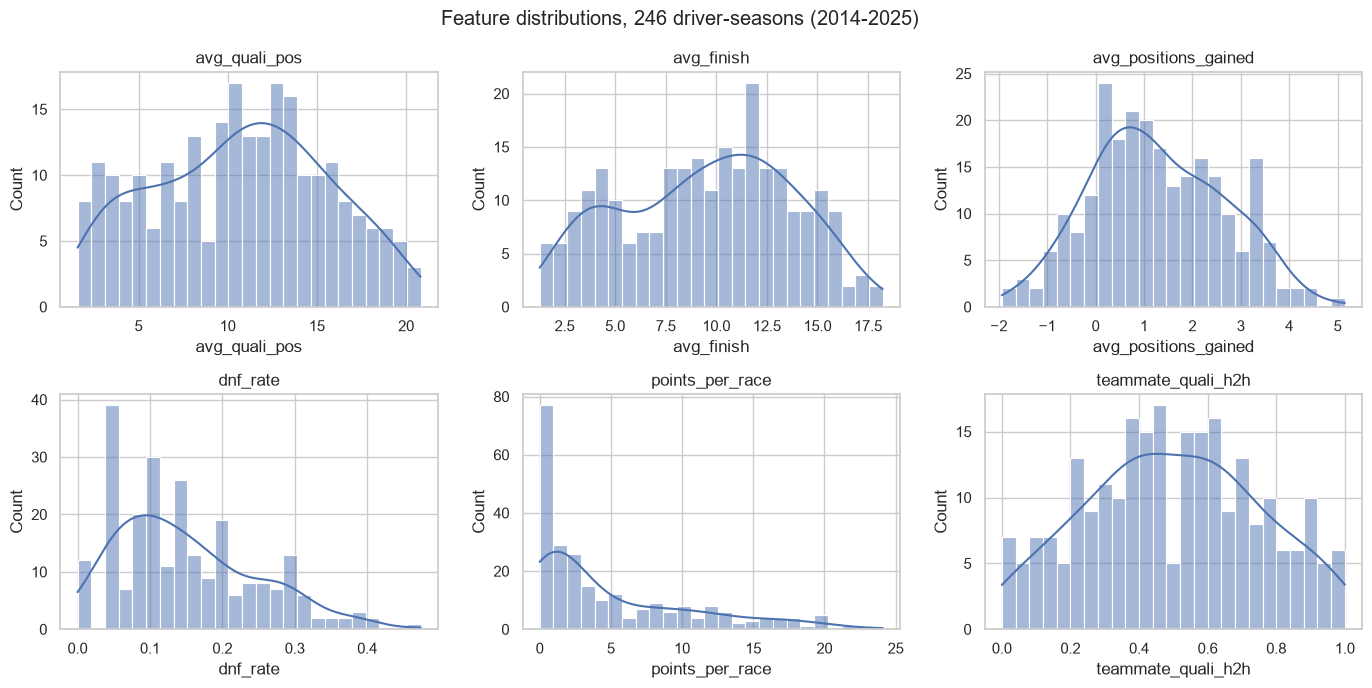

In [151]:
FEATURES = ["avg_quali_pos", "avg_finish", "avg_positions_gained",
            "dnf_rate", "points_per_race", "teammate_quali_h2h"]

display(season[FEATURES].describe().T.round(2))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(season[col], bins=25, kde=True, ax=ax)
    ax.set_title(col)
fig.suptitle(f"Feature distributions, {len(season)} driver-seasons ({START_YEAR}-{END_YEAR})")
fig.tight_layout()
fig.savefig(FIGURES / "feature_distributions.png", dpi=150)
plt.show()

### 2.9 Correlation check
Two near-identical features give that dimension double weight in the distance
computations of both algorithms. If a pair is above |r| = 0.85, we keep only one.

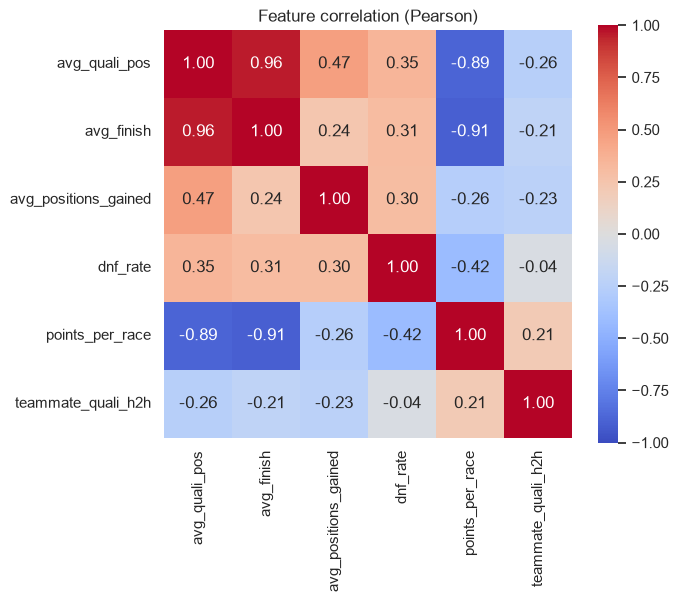

Pairs above |r| = 0.85: [('avg_quali_pos', 'avg_finish', np.float64(0.96)), ('avg_quali_pos', 'points_per_race', np.float64(-0.89)), ('avg_finish', 'points_per_race', np.float64(-0.91))]


In [152]:
corr = season[FEATURES].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Feature correlation (Pearson)")
plt.tight_layout()
plt.savefig(FIGURES / "feature_correlation.png", dpi=150)
plt.show()

high = [(a, b, round(corr.loc[a, b], 2))
        for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:]
        if abs(corr.loc[a, b]) > 0.85]
print("Pairs above |r| = 0.85:", high)

**Decision: keep 4 clustering features out of the 6 candidates.**

`avg_quali_pos`, `avg_finish` and `points_per_race` form a block of
near-duplicates (r = 0.96, −0.89 and −0.91). All three measure the same thing:
how far up the field the driver was that season. Keeping all three would give
this one dimension triple weight in the distance computations.

We keep **`avg_quali_pos`** because:
- it is measured **before** the race, so DNFs, safety cars and strategy do not affect it;
- its distribution is close to symmetric, while `points_per_race` is strongly
  right-skewed (the points scale rewards wins far more than midfield places);
- the points system changed during the era (2014 double points at the last race,
  an extra point for the fastest lap from 2019 to 2024), so points are not fully
  comparable between seasons.

`avg_finish` and `points_per_race` are **kept in the saved table** to describe the
clusters afterwards, but they are not given to the algorithms.

The remaining correlations are moderate (|r| ≤ 0.47), so each final feature brings
its own information:

| Feature | Measures |
|---|---|
| `avg_quali_pos` | pace (mostly car performance) |
| `avg_positions_gained` | racecraft: overtaking, race management |
| `dnf_rate` | reliability and incidents |
| `teammate_quali_h2h` | driver skill independent of the car |

In [153]:
FINAL_FEATURES = ["avg_quali_pos", "avg_positions_gained", "dnf_rate", "teammate_quali_h2h"]
season[FINAL_FEATURES].corr().round(2)

,avg_quali_pos,avg_positions_gained,dnf_rate,teammate_quali_h2h
avg_quali_pos,1.00,0.47,0.35,-0.26
avg_positions_gained,0.47,1.00,0.30,-0.23
dnf_rate,0.35,0.30,1.00,-0.04
teammate_quali_h2h,-0.26,-0.23,-0.04,1.00


### 2.10 Standardization
DBSCAN (through `eps`) and GMM both work with distances and variances. Without
scaling, `avg_quali_pos` (range ≈ 1–21) would outweigh `dnf_rate` (range 0–0.5)
just because of its units. `StandardScaler` gives every feature mean 0 and
standard deviation 1, so each one counts equally.

In [154]:
scaler = StandardScaler()
X = scaler.fit_transform(season[FINAL_FEATURES])
X_scaled = pd.DataFrame(X, columns=FINAL_FEATURES)

X_scaled.describe().T[["mean", "std"]].round(2)

,mean,std
avg_quali_pos,-0.0,1.0
avg_positions_gained,-0.0,1.0
dnf_rate,0.0,1.0
teammate_quali_h2h,0.0,1.0


### 2.11 Save the processed data
- `driver_seasons.csv`: readable features + interpretation columns
- `driver_seasons_scaled.csv`: the exact input of the algorithms, same row order

## 3. Implementation (charter point 5)

### 3.1 DBSCAN: choosing the parameters
DBSCAN has two parameters:
- `min_samples`: how many points must lie within `eps` of a point for it to be a
  **core point**. Rule of thumb: 2 × number of features = **8**.
- `eps`: the neighbourhood radius. We read it from a **k-distance plot**: for each
  point, the distance to its k-th nearest neighbour (k = `min_samples`), sorted.
  Where the curve bends sharply upward (the "elbow"), points stop having close
  neighbours: below it they sit in dense regions, above it they are isolated.

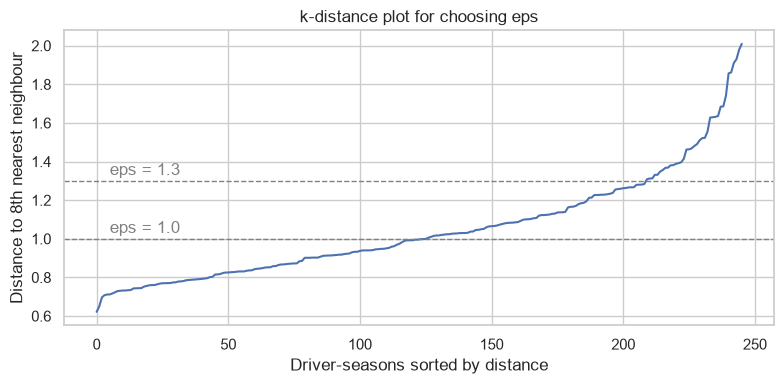

In [155]:
MIN_SAMPLES = 2 * X_scaled.shape[1]   # rule of thumb: 2 x number of features = 8

# n_neighbors = MIN_SAMPLES because the point itself counts as its first neighbour,
# exactly like in DBSCAN's definition of a core point
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])        # distance to the k-th neighbour, sorted

plt.figure(figsize=(8, 4))
plt.plot(k_dist)
for e in [1.0, 1.3]:
    plt.axhline(e, linestyle="--", linewidth=1, color="grey")
    plt.text(5, e + 0.03, f"eps = {e}", color="grey")
plt.xlabel("Driver-seasons sorted by distance")
plt.ylabel(f"Distance to {MIN_SAMPLES}th nearest neighbour")
plt.title("k-distance plot for choosing eps")
plt.tight_layout()
plt.savefig(FIGURES / "dbscan_k_distance.png", dpi=150)
plt.show()

### 3.2 DBSCAN: parameter grid
The elbow gives a starting point, not an exact value. We test a grid of `eps`
and `min_samples` values and record, for each one: the number of clusters, the
share of noise points, and the silhouette score (computed without noise points,
only when there are at least 2 clusters).

In [156]:
def dbscan_summary(eps, min_samples):
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    clustered = labels != -1                          # -1 = noise
    n_clusters = len(set(labels[clustered]))
    sil = (silhouette_score(X_scaled[clustered], labels[clustered])
           if n_clusters >= 2 else np.nan)            # silhouette needs 2+ clusters
    return {"eps": eps, "min_samples": min_samples, "clusters": n_clusters,
            "noise_%": round(100 * (~clustered).mean(), 1),
            "silhouette": round(sil, 3)}

grid = pd.DataFrame([dbscan_summary(round(eps, 1), ms)
                     for ms in [4, 5, 6, 8, 10]
                     for eps in np.arange(0.5, 1.45, 0.1)])

display(grid.pivot(index="eps", columns="min_samples", values="clusters"))
display(grid.pivot(index="eps", columns="min_samples", values="noise_%"))

min_samples,4,5,6,8,10
eps,,,,,
0.5,3,1,0,0,0
0.6,10,3,2,0,0
0.7,3,3,5,2,0
0.8,3,2,1,2,1
0.9,2,2,1,1,1
1.0,2,2,1,1,1
1.1,1,1,1,1,1
1.2,1,1,1,1,1
1.3,1,1,1,1,1


min_samples,4,5,6,8,10
eps,,,,,
0.5,92.7,97.6,100.0,100.0,100.0
0.6,72.8,90.2,95.1,100.0,100.0
0.7,49.2,55.7,66.3,91.5,100.0
0.8,28.5,32.5,39.8,55.3,74.8
0.9,15.9,21.5,26.8,35.0,41.1
1.0,6.9,9.3,14.2,22.4,26.4
1.1,5.3,5.3,5.7,10.2,15.0
1.2,3.3,3.3,3.7,5.7,7.7
1.3,2.4,2.4,2.4,2.4,2.8


In [157]:
DBSCAN_EPS, DBSCAN_MIN_SAMPLES = 1.0, 5

dbscan_labels = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES).fit_predict(X_scaled)
season["dbscan"] = dbscan_labels

pd.Series(dbscan_labels).value_counts().rename("driver-seasons").to_frame().T

,0,-1,1
driver-seasons,218,23,5


In [158]:
show = ["driver", "year", "team", "champ_pos"] + FINAL_FEATURES
season[season.dbscan != 0].sort_values(["dbscan", "year"])[show + ["dbscan"]].round(2)

,driver,year,team,champ_pos,avg_quali_pos,avg_positions_gained,dnf_rate,teammate_quali_h2h,dbscan
38,Adrian Sutil,2014,Sauber,18.0,15.21,-0.75,0.37,0.53,-1
58,Kamui Kobayashi,2014,Caterham,22.0,19.38,3.44,0.40,0.75,-1
68,Pastor Maldonado,2014,Lotus F1,16.0,17.68,4.38,0.28,0.21,-1
92,Max Chilton,2014,Marussia,21.0,19.69,3.38,0.19,0.20,-1
122,Marcus Ericsson,2014,Caterham,19.0,20.81,3.18,0.31,0.25,-1
16,Fernando Alonso,2015,McLaren,17.0,15.56,3.82,0.39,0.50,-1
26,Kimi Räikkönen,2015,Ferrari,4.0,6.89,1.00,0.26,0.21,-1
69,Pastor Maldonado,2015,Lotus F1,14.0,12.42,3.00,0.47,0.11,-1
18,Fernando Alonso,2017,McLaren,15.0,11.42,1.91,0.39,0.84,-1
62,Nico Hülkenberg,2017,Renault,10.0,9.55,-1.00,0.30,0.95,-1


### 3.3 DBSCAN: results and interpretation

**1. No density gaps.** Across the whole grid, no setting gives several large
clusters with little noise: either most points are noise (small `eps`), or
almost everything merges into a single cluster (large `eps`). The textbook
setting (`min_samples` = 8, `eps` at the elbow ≈ 1.3) gives **one cluster**.
Driver-seasons form a **continuum**: performance varies smoothly from the front
of the grid to the back, without empty regions between groups.

**2. Chosen setting: `eps` = 1.0, `min_samples` = 5.** It is the only setting
that gives 2 clusters with less than 10% noise: **218 seasons in the main
cluster, 5 in cluster 1, 23 noise points (9.3%)**.

**3. Cluster 1: drivers outperforming their car.** Russell 2020–21, Albon
2023–24 (all Williams) and Alonso 2025 (Aston Martin). They all beat their
teammate in qualifying almost every time (`teammate_quali_h2h` 0.91–1.00),
in midfield-to-slow cars (average qualifying 10–15), with almost no positions
gained in races (−0.2 to +0.7): they already qualify the car higher than it
deserves, so there is little left to gain on Sunday.

**4. Noise points: the exceptional seasons.** DBSCAN acts here as an **anomaly
detector**. The 23 noise points fall into recognizable patterns:

| Pattern | Examples | What makes them unusual |
|---|---|---|
| Fast car, driver beaten by teammate | Pérez 2023, Albon 2020, Räikkönen 2015 | top car (Pérez 2nd in the championship) but `h2h` 0.00–0.21; Pérez gained 5.15 places per race because he started too far back for his car |
| Unreliable car | Alonso 2015 & 2017 (McLaren-Honda), Ricciardo 2017–18 | `dnf_rate` 0.30–0.39: retired in 1 race out of 3; Ricciardo combined this with +4 places gained per race |
| Crash-prone driver | Maldonado 2015 | `dnf_rate` 0.47 (almost 1 race in 2 not finished) and `h2h` 0.11 |
| Back-of-grid in 2014 | Ericsson, Kobayashi (Caterham), Chilton (Marussia) | qualifying 19–21 with +3 places gained: mostly cars ahead retiring, not overtakes |

Several drivers near cluster 1 (Russell 2019, Albon 2022, Schumacher 2021) also
beat their teammate 90–100% of the time but in the slowest car, so they lie just
outside the dense region.

**Limitation:** `teammate_quali_h2h` is relative. Beating a weak teammate inflates
it, so it measures "better than the teammate", not absolute skill.

### 3.4 Gaussian Mixture Model: choosing the parameters
A GMM assumes the data comes from a mix of K Gaussian distributions and fits
them with the **EM algorithm** (Expectation: compute each point's probability of
belonging to each component; Maximization: update each component's mean,
covariance and weight; repeat until stable).

Two parameters to choose:
- `n_components` (K): the number of Gaussians.
- `covariance_type`: the shape each Gaussian may take:
  `spherical` (round, one variance), `diag` (axis-aligned ellipses),
  `tied` (all components share one shape), `full` (any ellipse, most flexible).

We choose both with the **BIC** (Bayesian Information Criterion): it rewards a
good fit to the data but penalizes the number of parameters, so it protects
against overfitting. **Lower BIC = better model.**

,spherical,diag,tied,full
n_components,,,,
1,2820.0,2837.0,2747.0,2747.0
2,2733.0,2736.0,2764.0,2765.0
3,2742.0,2751.0,2743.0,2811.0
4,2748.0,2777.0,2759.0,2872.0
5,2760.0,2815.0,2778.0,2918.0
6,2769.0,2842.0,2790.0,2966.0
7,2787.0,2874.0,2814.0,3023.0
8,2810.0,2910.0,2833.0,3065.0


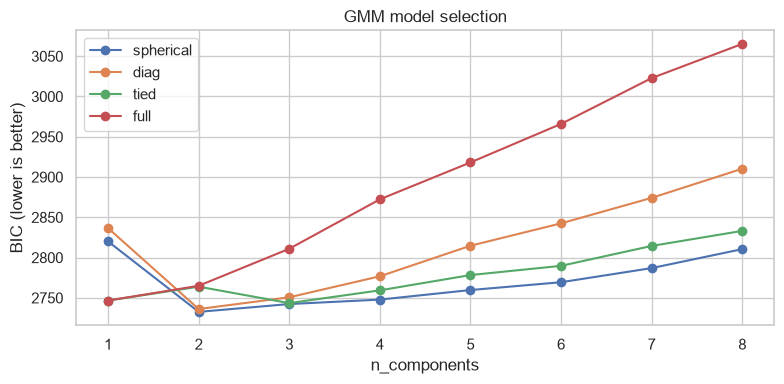

Lowest BIC: 2733 with n_components=2, covariance_type='spherical'


In [159]:
COV_TYPES = ["spherical", "diag", "tied", "full"]
K_RANGE = range(1, 9)

bic = pd.DataFrame(index=K_RANGE, columns=COV_TYPES, dtype=float)
for cov in COV_TYPES:
    for k in K_RANGE:
        gmm = GaussianMixture(n_components=k, covariance_type=cov,
                              n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
        bic.loc[k, cov] = gmm.bic(X_scaled)

bic.index.name = "n_components"
display(bic.round(0))

ax = bic.plot(marker="o", figsize=(8, 4))
ax.set_ylabel("BIC (lower is better)")
ax.set_title("GMM model selection")
plt.tight_layout()
plt.savefig(FIGURES / "gmm_bic.png", dpi=150)
plt.show()

best_k, best_cov = bic.stack().idxmin()
print(f"Lowest BIC: {bic.loc[best_k, best_cov]:.0f} with n_components={best_k}, covariance_type='{best_cov}'")

In [160]:
gmm = GaussianMixture(n_components=best_k, covariance_type=best_cov,
                      n_init=10, random_state=RANDOM_STATE).fit(X_scaled)

season["gmm"] = gmm.predict(X_scaled)           # hard label: most likely component
proba = gmm.predict_proba(X_scaled)             # soft labels: one probability per component
season["gmm_confidence"] = proba.max(axis=1)    # probability of the chosen component

print(f"Converged: {gmm.converged_} after {gmm.n_iter_} iterations")
season.gmm.value_counts().rename("driver-seasons").to_frame().T

Converged: True after 6 iterations


gmm,0,1
driver-seasons,154,92


In [161]:
PROFILE = FINAL_FEATURES + ["avg_finish", "points_per_race", "champ_pos"]
profile = season.groupby("gmm")[PROFILE].mean().round(2)
profile["size"] = season.gmm.value_counts()
profile

,avg_quali_pos,avg_positions_gained,dnf_rate,teammate_quali_h2h,avg_finish,points_per_race,champ_pos,size
gmm,,,,,,,,
0,13.14,1.92,0.19,0.43,11.23,2.43,13.60,154
1,6.63,0.19,0.08,0.61,6.55,9.27,6.29,92


In [162]:
UNCERTAIN = 0.65    # below this, the model hesitates between the two components

front = profile.avg_quali_pos.idxmin()           # the component with the best qualifying
season["p_front"] = proba[:, front]

uncertain = season[season.gmm_confidence < UNCERTAIN]
print(f"{len(uncertain)} driver-seasons with confidence below {UNCERTAIN}")
uncertain.sort_values("p_front")[["driver", "year", "team", "champ_pos"]
                                 + FINAL_FEATURES + ["p_front"]].round(2)

24 driver-seasons with confidence below 0.65


,driver,year,team,champ_pos,avg_quali_pos,avg_positions_gained,dnf_rate,teammate_quali_h2h,p_front
216,Alexander Albon,2023,Williams,13.0,12.41,0.67,0.18,1.00,0.36
224,Yuki Tsunoda,2023,AlphaTauri,14.0,13.45,1.35,0.09,0.73,0.36
192,Charles Leclerc,2020,Ferrari,8.0,8.29,1.00,0.24,0.76,0.41
164,Esteban Ocon,2021,Alpine F1 Team,11.0,11.00,1.11,0.14,0.50,0.41
161,Esteban Ocon,2017,Force India,8.0,10.15,1.53,0.05,0.35,0.43
49,Sebastian Vettel,2021,Aston Martin,12.0,11.77,1.11,0.14,0.64,0.44
88,Daniel Ricciardo,2021,McLaren,8.0,9.64,1.52,0.05,0.32,0.44
146,Carlos Sainz,2020,McLaren,6.0,8.29,1.79,0.12,0.47,0.45
71,Sergio Pérez,2015,Force India,9.0,10.68,1.56,0.05,0.42,0.46
29,Kimi Räikkönen,2018,Ferrari,3.0,3.86,0.47,0.19,0.19,0.47


### 3.5 GMM: results and interpretation

**1. Model choice (BIC).** The lowest BIC is **2 spherical components (2733)**.
Diagonal covariance with 2 components is practically tied (2736): a BIC gap of 3
is negligible, so we keep the simpler model (spherical: one variance per component,
fewer parameters). Two signs that the structure is weak:
- with the most flexible shape (`full`), the best model has **K = 1**, i.e. no clusters;
- the best 2-component model beats the best 1-component model by only 14 BIC points.

This agrees with DBSCAN: the data is close to a continuum, and the GMM split is
a division of that continuum, not a gap between groups.

**2. The two components** (Cell 48):

| | Front & clean (92 seasons) | Rest of the field (154 seasons) |
|---|---|---|
| Avg qualifying | 6.6 | 13.1 |
| Positions gained | +0.2 | +1.9 |
| DNF rate | 0.08 | 0.19 |
| Teammate h2h | 0.61 | 0.43 |

The split is not only "front vs back": the first component is also **reliable**
(less than half the DNF rate) and **gains few places** (starting near the front
leaves little room to gain). It describes **clean, consistent seasons**. That is
why Bottas 2024 at Sauber (22nd in the championship, qualifying 15.2) sits on the
border (p_front = 0.54): his low DNF rate (0.08), almost zero positions gained
and strong head-to-head (0.88) pull him toward this component despite his slow car.

**3. Validation on columns the model never saw.** Average finish 6.6 vs 11.2,
points per race 9.3 vs 2.4, championship position 6.3 vs 13.6. These columns were
not given to the GMM, yet they separate clearly: the components capture real
performance differences.

**4. Uncertain seasons (soft clustering).** 24 seasons have a confidence below
0.65, mostly in the **midfield** (qualifying 8–14): the boundary falls exactly
where a continuum would put it. Examples:
- **Verstappen 2020** (p_front = 0.49): front-runner pace (3.1) and a perfect
  head-to-head (1.00) pull him to the front group, but his DNF rate (0.29) is
  typical of the rest of the field.
- **Räikkönen 2018** (p_front = 0.47): qualifying 3.9 in a Ferrari, but beaten
  by his teammate 81% of the time (h2h 0.19) and a 0.19 DNF rate.
- **Albon 2023** (p_front = 0.36) vs **Alonso 2025** (0.64): both beat their
  teammate every time (h2h 1.00) in midfield cars; Alonso qualified two places
  higher on average (10.4 vs 12.4), which tips him toward the front group.

DBSCAN cannot express this hesitation: it only says "in a cluster" or "noise".

## 4. Evaluation (charter point 6)

Without true labels, we use **internal metrics**, which judge a clustering by its geometry:

| Metric | Measures | Range | Better |
|---|---|---|---|
| Silhouette | how much closer each point is to its own cluster than to the nearest other one | −1 to 1 | higher |
| Davies-Bouldin | average similarity between each cluster and its most similar neighbour | ≥ 0 | lower |
| Calinski-Harabasz | ratio of between-cluster to within-cluster dispersion | ≥ 0 | higher |

**DBSCAN noise:** the metrics are computed without noise points (they belong to no
cluster), and the noise share is reported separately. For a fair comparison, GMM is
also scored on the **same points** DBSCAN kept.

In [163]:
def scores(X, labels):
    return {"silhouette": silhouette_score(X, labels),
            "davies_bouldin": davies_bouldin_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels)}

kept = (season.dbscan != -1).to_numpy()     # points DBSCAN assigned to a cluster

evaluation = pd.DataFrame({
    "DBSCAN (without noise)":     scores(X_scaled[kept], season.dbscan[kept]),
    "GMM (all points)":           scores(X_scaled, season.gmm),
    "GMM (same points as DBSCAN)": scores(X_scaled[kept], season.gmm[kept]),
}).T

evaluation["clusters"] = [season.dbscan[kept].nunique(), season.gmm.nunique(), season.gmm[kept].nunique()]
evaluation["noise_%"] = [round(100 * (~kept).mean(), 1), 0, 0]
evaluation.round(3)

,silhouette,davies_bouldin,calinski_harabasz,clusters,noise_%
DBSCAN (without noise),0.099,1.030,6.697,2,9.3
GMM (all points),0.259,1.333,105.509,2,0.0
GMM (same points as DBSCAN),0.278,1.320,107.037,2,0.0


In [164]:
# Cross-table: how DBSCAN groups are spread across GMM components
display(pd.crosstab(season.dbscan, season.gmm,
                    rownames=["DBSCAN"], colnames=["GMM"], margins=True))

# Adjusted Rand Index: 1 = identical partitions, 0 = no more agreement than chance
ari = adjusted_rand_score(season.dbscan[kept], season.gmm[kept])
print(f"Adjusted Rand Index (DBSCAN vs GMM, without noise): {ari:.3f}")

GMM,0,1,All
DBSCAN,,,
-1,23,0,23
0,127,91,218
1,4,1,5
All,154,92,246


Adjusted Rand Index (DBSCAN vs GMM, without noise): -0.007


Variance explained: PC1 47%, PC2 24%, total 71%


,avg_quali_pos,avg_positions_gained,dnf_rate,teammate_quali_h2h
PC1,0.59,0.57,0.45,-0.35
PC2,0.02,0.00,0.59,0.81


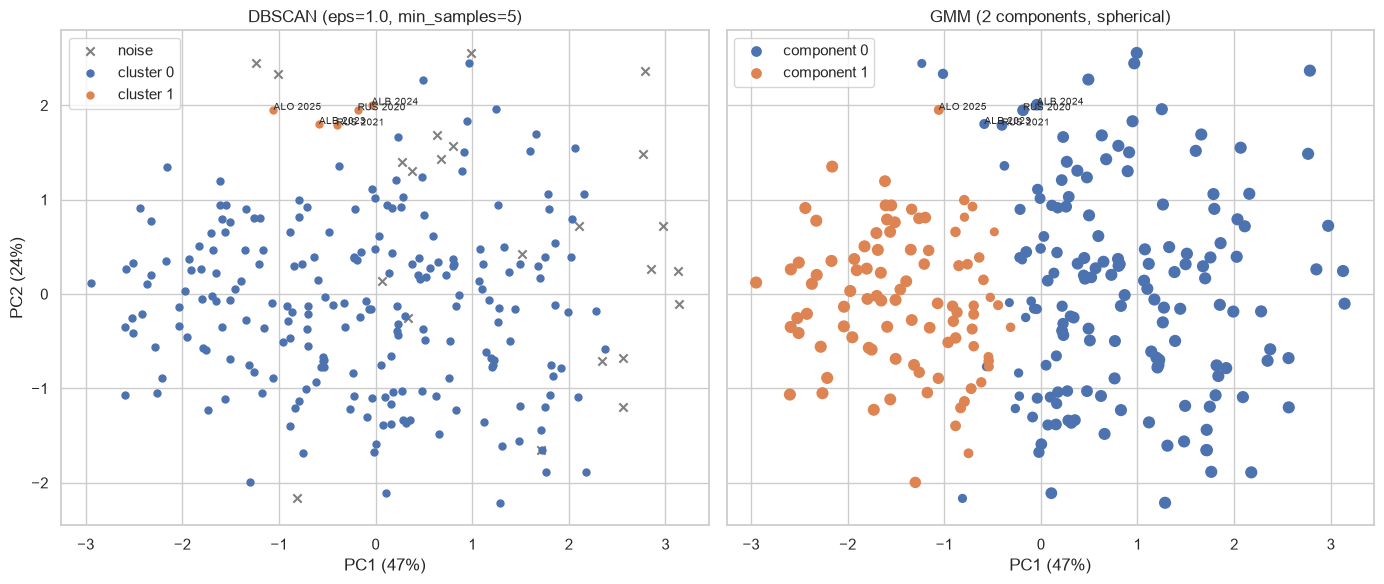

In [165]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_scaled)
season["pc1"], season["pc2"] = coords[:, 0], coords[:, 1]

explained = pca.explained_variance_ratio_
print(f"Variance explained: PC1 {explained[0]:.0%}, PC2 {explained[1]:.0%}, total {explained.sum():.0%}")
display(pd.DataFrame(pca.components_, columns=FINAL_FEATURES, index=["PC1", "PC2"]).round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

# Left: DBSCAN (noise in grey crosses)
noise = season.dbscan == -1
axes[0].scatter(season.pc1[noise], season.pc2[noise], c="grey", marker="x", label="noise")
for lab in sorted(season.dbscan[~noise].unique()):
    pts = season[season.dbscan == lab]
    axes[0].scatter(pts.pc1, pts.pc2, s=25, label=f"cluster {lab}")
axes[0].set_title(f"DBSCAN (eps={DBSCAN_EPS}, min_samples={DBSCAN_MIN_SAMPLES})")

# Right: GMM, point size = confidence (small points = uncertain)
for lab in sorted(season.gmm.unique()):
    pts = season[season.gmm == lab]
    axes[1].scatter(pts.pc1, pts.pc2, s=60 * pts.gmm_confidence, label=f"component {lab}")
axes[1].set_title(f"GMM ({best_k} components, {best_cov})")

# Name a few seasons discussed in the interpretation
for _, r in season[season.dbscan == 1].iterrows():
    for ax in axes:
        ax.annotate(f"{r.code} {r.year}", (r.pc1, r.pc2), fontsize=7)

for ax in axes:
    ax.set_xlabel(f"PC1 ({explained[0]:.0%})")
    ax.legend()
axes[0].set_ylabel(f"PC2 ({explained[1]:.0%})")
fig.tight_layout()
fig.savefig(FIGURES / "clusters_pca.png", dpi=150)
plt.show()

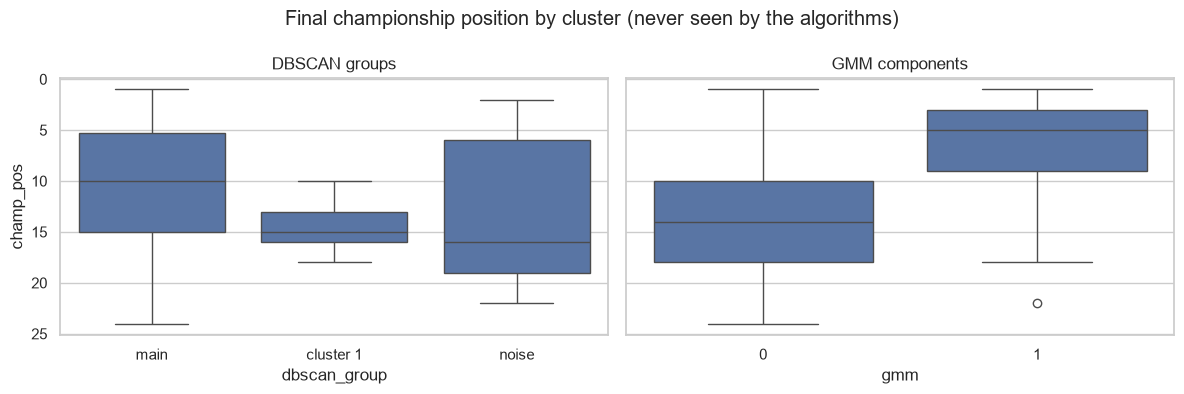

In [166]:
season["dbscan_group"] = season.dbscan.map({-1: "noise", 0: "main", 1: "cluster 1"})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.boxplot(data=season, x="dbscan_group", y="champ_pos", ax=axes[0], order=["main", "cluster 1", "noise"])
sns.boxplot(data=season, x="gmm", y="champ_pos", ax=axes[1])
axes[0].set_title("DBSCAN groups")
axes[1].set_title("GMM components")
axes[0].invert_yaxis()      # P1 at the top
fig.suptitle("Final championship position by cluster (never seen by the algorithms)")
fig.tight_layout()
fig.savefig(FIGURES / "champ_pos_by_cluster.png", dpi=150)
plt.show()

### Evaluation summary

**Metrics disagree, and each disagreement has a reason:**
- **Silhouette** favours GMM (0.26 vs 0.10). By the usual reading (> 0.5 strong,
  0.25–0.5 weak, < 0.25 no substantial structure), GMM finds a **weak** structure
  and DBSCAN's partition **no substantial** one.
- **Calinski-Harabasz** strongly favours GMM (105 vs 7): it rewards large, balanced,
  well-separated groups, and DBSCAN has one cluster of 218 and one of 5.
- **Davies-Bouldin** favours DBSCAN (1.03 vs 1.33): its small cluster 1 is compact
  and far from the main centre, which this metric rewards even though it holds
  only 5 seasons.

No single metric is enough, which is why we report all three and the noise share.

**The two algorithms find different structures** (ARI ≈ 0): GMM cuts along PC1
(front & clean vs rest of the field), and DBSCAN isolates seasons at the edges,
plus a small "driver beats car" group high on PC2.

**External check:** GMM components line up with championship position (never seen
by the model); DBSCAN groups don't, because DBSCAN looks for unusual profiles, not
for results.

## 5. Comparison and interpretation (charter point 7)

| | DBSCAN | GMM |
|---|---|---|
| How it works | groups points that are packed close together | fits 2 bell curves and gives each point a probability |
| Number of groups | found by itself | chosen with BIC |
| Result here | 1 big group + 5 seasons + 23 outliers | 2 groups: front & clean (92) vs rest (154) |
| Outliers | yes, marked as noise | no, every season is forced into a group |
| Soft labels | no | yes (probability per group) |
| Silhouette | 0.10 | 0.26 |
| Matches championship position | no | yes |

In [167]:
cols = FINAL_FEATURES + ["points_per_race", "champ_pos"]

print("DBSCAN groups")
display(season.groupby("dbscan_group")[cols].mean().round(2)
              .assign(size=season.dbscan_group.value_counts()))

print("GMM components")
display(season.groupby("gmm")[cols].mean().round(2)
              .assign(size=season.gmm.value_counts()))

DBSCAN groups


,avg_quali_pos,avg_positions_gained,dnf_rate,teammate_quali_h2h,points_per_race,champ_pos,size
dbscan_group,,,,,,,
cluster 1,12.63,0.31,0.22,0.95,0.94,14.40,5
main,10.45,1.17,0.14,0.49,5.23,10.54,218
noise,12.73,2.49,0.27,0.46,3.55,13.26,23


GMM components


,avg_quali_pos,avg_positions_gained,dnf_rate,teammate_quali_h2h,points_per_race,champ_pos,size
gmm,,,,,,,
0,13.14,1.92,0.19,0.43,2.43,13.60,154
1,6.63,0.19,0.08,0.61,9.27,6.29,92


### Which model is better?

**For grouping seasons by performance level, GMM is the better model:**
- better silhouette (0.26 vs 0.10) and Calinski-Harabasz (105 vs 7);
- its groups match points and championship position, which it never saw;
- its probabilities show the midfield seasons that sit between the two groups.

**DBSCAN is still useful, for another job:** finding unusual seasons.
Its 23 outliers are real special cases: Pérez 2023 (top car, beaten by his teammate),
Maldonado 2015 (almost one crash every two races), Alonso 2015 (unreliable car).
GMM hides these seasons inside its big group.

**Why they disagree (ARI ≈ 0):** the data has no empty space between groups.
DBSCAN needs empty space to separate groups, so it finds almost one group.
GMM always splits the data into K groups, so it cuts the continuum in two.

## 6. Conclusion

- F1 driver-seasons (2014–2025) do not form clearly separated groups: performance
  changes smoothly from the front to the back of the grid.
- GMM gives the most useful grouping: **front & clean** seasons vs **rest of the field**.
- DBSCAN works best as an **outlier detector**, finding exceptional seasons.
- The two algorithms are complementary, not competitors.

**Limitations**
- Teammate head-to-head depends on the teammate: beating a weak teammate looks strong.
- Positions gained is higher at the back (cars ahead retire, and the pole sitter cannot gain).
- 246 seasons and 4 features: a small dataset.

**Possible improvements**
- Add race pace from `lap_times` (gap to the teammate per lap).
- Try HDBSCAN, which handles groups of different density.